# SCT ML Task 1 — House Price Prediction (Linear Regression)
**Internship:** SkillCraft Technology · Machine Learning  
**Objective:** Predict house sale price from **square footage, number of bedrooms and number of bathrooms** using Linear Regression.

**Dataset:** Ames Housing data, as used in the Kaggle competition *House Prices: Advanced Regression Techniques* (`train.csv`, 1,460 houses, 81 columns). Original source: Dean De Cock (2011), Ames, Iowa Assessor's data. Kaggle page: https://www.kaggle.com/c/house-prices-advanced-regression-techniques/data  
This notebook downloads a public GitHub copy of `train.csv` (no login needed).

| Column used | Meaning |
|---|---|
| `GrLivArea` | Above-ground living area in sq ft → **square footage** |
| `BedroomAbvGr` | Bedrooms above ground → **bedrooms** |
| `FullBath`, `HalfBath` | Full and half bathrooms → combined into **bathrooms** (half bath counts 0.5) |
| `SalePrice` | Sale price in USD → **target** |

## 1. Imports

In [ ]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
SEED = 42
np.random.seed(SEED)
%matplotlib inline

## 2. Load and inspect the data
If the download fails, upload `train.csv` to the Colab file panel and re-run this cell.

In [ ]:
URL = "https://raw.githubusercontent.com/manavkapadnis/House-prices-Advanced-regression-techniques/master/train.csv"
try:
    df_raw = pd.read_csv("train.csv") if os.path.exists("train.csv") else pd.read_csv(URL)
except Exception as e:
    raise SystemExit(f"Could not load data ({e}). Download train.csv from Kaggle and upload it to Colab.")

needed = ["GrLivArea", "BedroomAbvGr", "FullBath", "HalfBath", "SalePrice"]
missing_cols = [c for c in needed if c not in df_raw.columns]
assert not missing_cols, f"Missing columns: {missing_cols}"

print("Full dataset shape:", df_raw.shape)
df = df_raw[needed].copy()
df.head()

Full dataset shape: (1460, 81)


,GrLivArea,BedroomAbvGr,FullBath,HalfBath,SalePrice
0,1710,3,2,1,208500
1,1262,3,2,0,181500
2,1786,3,2,1,223500
3,1717,3,1,0,140000
4,2198,4,2,1,250000


In [ ]:
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   GrLivArea     1460 non-null   int64
 1   BedroomAbvGr  1460 non-null   int64
 2   FullBath      1460 non-null   int64
 3   HalfBath      1460 non-null   int64
 4   SalePrice     1460 non-null   int64
dtypes: int64(5)
memory usage: 57.2 KB


,count,mean,std,min,25%,50%,75%,max
GrLivArea,1460.0,1515.463699,525.480383,334.0,1129.5,1464.0,1776.75,5642.0
BedroomAbvGr,1460.0,2.866438,0.815778,0.0,2.0,3.0,3.00,8.0
FullBath,1460.0,1.565068,0.550916,0.0,1.0,2.0,2.00,3.0
HalfBath,1460.0,0.382877,0.502885,0.0,0.0,0.0,1.00,2.0
SalePrice,1460.0,180921.195890,79442.502883,34900.0,129975.0,163000.0,214000.00,755000.0


## 3. Clean the data
Checks: missing values, duplicates, and invalid records (a house with 0 bedrooms or no bathroom, non-positive area/price).  
We also drop houses above 4,000 sq ft: the dataset's author documents them as unusual sales (partial sales) that distort linear models.

In [ ]:
print("Missing values per column:\n", df.isna().sum(), "\n")
print("Duplicate rows:", df.duplicated().sum())

df["Bathrooms"] = df["FullBath"] + 0.5 * df["HalfBath"]
before = len(df)
df = df.dropna()
df = df[(df["GrLivArea"] > 0) & (df["SalePrice"] > 0) & (df["BedroomAbvGr"] > 0) & (df["Bathrooms"] > 0)]
df = df[df["GrLivArea"] < 4000]
print(f"Rows kept: {len(df)} of {before} (removed {before-len(df)} invalid/outlier rows)")

Missing values per column:
 GrLivArea       0
BedroomAbvGr    0
FullBath        0
HalfBath        0
SalePrice       0
dtype: int64 

Duplicate rows: 4
Rows kept: 1449 of 1460 (removed 11 invalid/outlier rows)


## 4. Exploratory data analysis

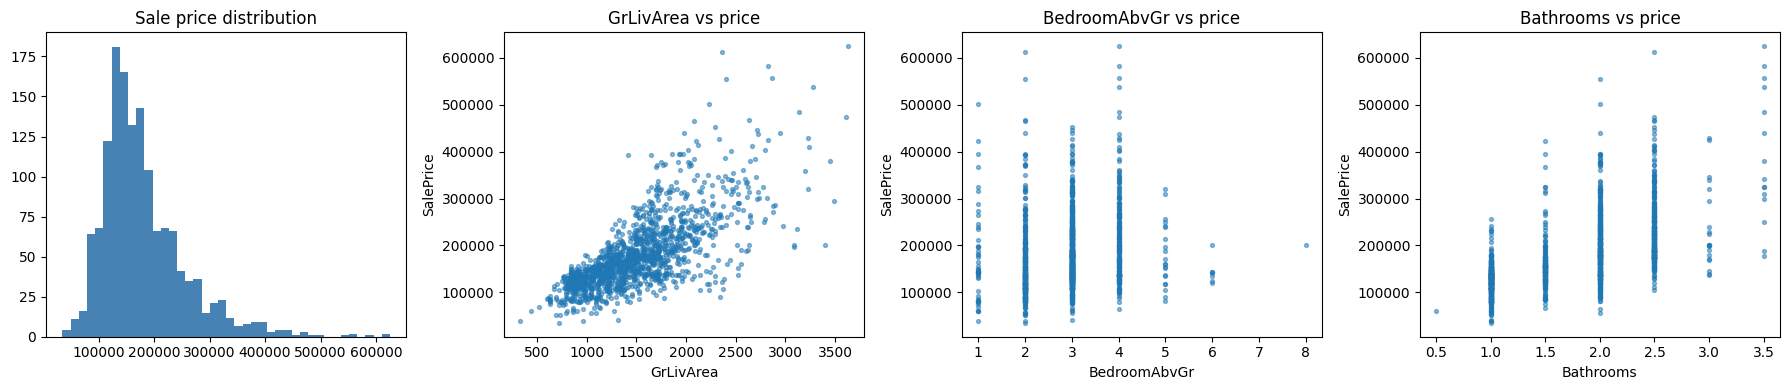

Correlation with SalePrice:
SalePrice       1.000000
GrLivArea       0.720908
Bathrooms       0.606548
BedroomAbvGr    0.170996
Name: SalePrice, dtype: float64


In [ ]:
features = ["GrLivArea", "BedroomAbvGr", "Bathrooms"]
target = "SalePrice"

fig, ax = plt.subplots(1, 4, figsize=(18, 4))
ax[0].hist(df[target], bins=40, color="steelblue"); ax[0].set_title("Sale price distribution")
for a, f in zip(ax[1:], features):
    a.scatter(df[f], df[target], s=8, alpha=0.5); a.set_xlabel(f); a.set_ylabel("SalePrice"); a.set_title(f"{f} vs price")
plt.tight_layout(); plt.show()

print("Correlation with SalePrice:")
print(df[features + [target]].corr()[target].sort_values(ascending=False))

## 5. Train/test split and model training
80% of houses train the model; 20% are held back to test it on unseen data.

In [ ]:
X, y = df[features], df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print("Train:", X_train.shape, " Test:", X_test.shape)

model = LinearRegression().fit(X_train, y_train)
print("Intercept:", round(model.intercept_, 2))
for f, c in zip(features, model.coef_):
    print(f"  {f:14s} coefficient = {c:,.2f}")

Train: (1159, 3)  Test: (290, 3)
Intercept: 54583.53
  GrLivArea      coefficient = 118.70
  BedroomAbvGr   coefficient = -31,107.51
  Bathrooms      coefficient = 20,747.65


## 6. Evaluation (on the unseen test set)

In [ ]:
pred = model.predict(X_test)
mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)
print(f"MAE  : ${mae:,.0f}   (average absolute error)")
print(f"RMSE : ${rmse:,.0f}   (penalises large errors more)")
print(f"R²   : {r2:.3f}      (share of price variation explained)")
print(f"Baseline MAE if we always guessed the mean price: ${mean_absolute_error(y_test, np.full(len(y_test), y_train.mean())):,.0f}")

MAE  : $36,796   (average absolute error)
RMSE : $51,067   (penalises large errors more)
R²   : 0.602      (share of price variation explained)
Baseline MAE if we always guessed the mean price: $59,435


In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.5, s=14)
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual price ($)"); plt.ylabel("Predicted price ($)")
plt.title("Actual vs Predicted House Prices (test set)"); plt.legend(); plt.show()

## 7. Sample prediction

In [ ]:
sample = pd.DataFrame({"GrLivArea": [1800], "BedroomAbvGr": [3], "Bathrooms": [2.5]})
print(sample.to_string(index=False))
print(f"Predicted price: ${model.predict(sample)[0]:,.0f}")

 GrLivArea  BedroomAbvGr  Bathrooms
      1800             3        2.5
Predicted price: $226,787


## 8. Interpretation and limitations
- Each coefficient is the average price change for a one-unit increase in that feature **holding the others fixed**.
- Living area is by far the strongest predictor. Bedrooms can show a small or even negative coefficient: it is correlated with area, so once area is known an extra bedroom (a smaller average room) adds little.
- **Limitations:** only 3 features (location, quality, age, lot size are ignored); assumes straight-line relationships; sensitive to outliers; data is from one city (Ames, Iowa, 2006–2010) so it should **not** be used to price houses elsewhere.
- **Improvements:** add neighbourhood, overall quality and year built; use log(price); try Ridge/Lasso or tree-based models.

## 9. Conclusion
A Linear Regression model using area, bedrooms and bathrooms was trained and tested on held-out data; the metrics above show how well this simple model explains price and where it falls short.